# New Jersey 2024 General Election Precinct Conversion

Combine 21 county CSVs into a statewide results CSV for President, U.S. Senate,
and U.S. House, then join the results to precinct boundaries. Aggregate reporting
groups remain separate in the CSV; their votes are allocated to precincts in the shapefiles.

These are initial joined shapefiles, before any additional manual edits to align
precinct boundaries with voter-file locations. Edits already present in the input
shapefiles are retained. Geometry issues are reported without repair.

**Inputs:** County CSVs in `data/results`, boundaries in `data/boundaries`,
and matching and validation tables in `data/crosswalks` and `data/reference`.

**Outputs:** `output/nj_2024_gen_prec.csv`, an allocated CSV for each spatial layer,
and `output/nj_2024_gen_prec.zip` containing the all-contest and congressional shapefiles.

Validation checks 6,849 reporting units, 6,408 precinct features, and 6,410
congressional features, with vote totals preserved by county and candidate.

## Setup

Run from the folder containing `data/`. Requires pandas, GeoPandas, Shapely,
Matplotlib, and IPython.

In [1]:
from __future__ import annotations

import json
import re
import zipfile
from collections import defaultdict
from pathlib import Path

import geopandas as gpd
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import shapely
from shapely import normalize

ROOT = Path.cwd()
DATA_DIR = ROOT / "data/results"
OUTPUT_DIR = ROOT / "output"
OUTPUT_PATH = OUTPUT_DIR / "nj_2024_gen_prec.csv"
SHAPE_PATH = ROOT / "data/boundaries/New_Jersey_Statewide_Precincts.shp"
CONG_PATH = ROOT / "data/boundaries/nj_congressional.shp"
LOOKUP_PATH = ROOT / "data/reference/municipality_lookup.json"
CROSSWALK_DIR = ROOT / "data/crosswalks"
CONTROLS_PATH = ROOT / "data/reference/official_controls.csv"
README_PATH = ROOT / "data/reference/results_readme.txt"
SHAPEFILE_DIR = OUTPUT_DIR / "nj_2024_gen_prec"

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", None)
OUTPUT_DIR.mkdir(exist_ok=True)
SHAPEFILE_DIR.mkdir(exist_ok=True)

In [2]:
EXPECTED_FILES = 21
EXPECTED_ROWS = 6_849
EXPECTED_VOTE_FIELDS = 69
INPUT_COLUMNS = ["county", "precinct", "office", "district", "party", "candidate", "votes"]

COUNTY_FIPS = {
    "Atlantic": "001",
    "Bergen": "003",
    "Burlington": "005",
    "Camden": "007",
    "Cape May": "009",
    "Cumberland": "011",
    "Essex": "013",
    "Gloucester": "015",
    "Hudson": "017",
    "Hunterdon": "019",
    "Mercer": "021",
    "Middlesex": "023",
    "Monmouth": "025",
    "Morris": "027",
    "Ocean": "029",
    "Passaic": "031",
    "Salem": "033",
    "Somerset": "035",
    "Sussex": "037",
    "Union": "039",
    "Warren": "041",
}


CANDIDATES = pd.DataFrame(
    [
        ("PRE", "Kamala D. Harris", "Democratic", "G24PREDHAR", 2220713),
        ("PRE", "Donald J. Trump", "Republican", "G24PRERTRU", 1968215),
        ("PRE", "Jill Stein", "Green Party", "G24PREGSTE", 39041),
        ("PRE", "Robert F. Kennedy Jr.", "Independent/unaffiliated", "G24PREIKEN", 23479),
        ("PRE", "Chase Oliver", "Libertarian Party", "G24PRELOLI", 10500),
        ("PRE", "Claudia De La Cruz", "Socialism and Liberation", "G24PRESCRU", 5105),
        ("PRE", "Randall A. Terry", "U.S. Constitution Party", "G24PRECTER", 3024),
        ("PRE", "Joseph Kishore", "Socialist Equality", "G24PREEKIS", 1371),
        ("PRE", "Rachele Fruit", "Socialist Workers Party", "G24PREWFRU", 1277),
        ("USS", "Andy Kim", "Democratic", "G24USSDKIM", 2161491),
        ("USS", "Curtis Bashaw", "Republican", "G24USSRBAS", 1773589),
        ("USS", "Christina Khalil", "Green Party", "G24USSGKHA", 45443),
        ("USS", "Kenneth R. Kaplan", "Libertarian Party", "G24USSLKAP", 24242),
        ("USS", "Patricia G. Mooneyham", "Independent/unaffiliated", "G24USSIMOO", 17224),
        ("USS", "Joanne Kuniansky", "Socialist Workers Party", "G24USSWKUN", 9806),
        ("CON01", "Donald Norcross", "Democratic", "GCON01DNOR", 208808),
        ("CON01", 'Theodore "Teddy" Liddell', "Republican", "GCON01RLID", 144390),
        ("CON01", "Robin Brownfield", "Green Party", "GCON01GBRO", 5771),
        ("CON01", "Austin Johnson", "Independent/unaffiliated", "GCON01IJOH", 2091),
        ("CON02", "Jeff Van Drew", "Republican", "GCON02RVAN", 215946),
        ("CON02", "Joseph F. Salerno", "Democratic", "GCON02DSAL", 153117),
        ("CON02", "Thomas Cannavo", "Green Party", "GCON02GCAN", 2557),
        ("CON03", "Herb Conaway", "Democratic", "GCON03DCON", 202034),
        ("CON03", "Rajesh Mohan", "Republican", "GCON03RMOH", 169454),
        ("CON03", "Steven Welzer", "Green Party", "GCON03GWEL", 3478),
        ("CON03", "Chris Russomanno", "Libertarian Party", "GCON03LRUS", 1951),
        ("CON03", "Douglas Anthony Wynn", "Independent/unaffiliated", "GCON03IWYN", 1332),
        ("CON03", "Justin R. Barbera", "Independent/unaffiliated", "GCON03IBAR", 1235),
        ("CON04", "Christopher H. Smith", "Republican", "GCON04RSMI", 265652),
        ("CON04", "Matthew Jenkins", "Democratic", "GCON04DJEN", 124803),
        ("CON04", "John Morrison", "Libertarian Party", "GCON04LMOR", 1950),
        ("CON04", "Barry Bendar", "Green Party", "GCON04GBEN", 1823),
        ("CON05", "Josh Gottheimer", "Democratic", "GCON05DGOT", 208359),
        ("CON05", "Mary Jo Guinchard", "Republican", "GCON05RGUI", 165287),
        ("CON05", "Beau Forte", "Green Party", "GCON05GFOR", 3428),
        ("CON05", "James Tosone", "Libertarian Party", "GCON05LTOS", 2440),
        ("CON05", "Aamir Arif", "Independent/unaffiliated", "GCON05IARI", 2375),
        ("CON06", "Frank Pallone Jr.", "Democratic", "GCON06DPAL", 170275),
        ("CON06", "Scott Fegler", "Republican", "GCON06RFEG", 122519),
        ("CON06", "Fahad Akhtar", "Independent/unaffiliated", "GCON06IAKH", 4871),
        ("CON06", "Herb Tarbous", "Green Party", "GCON06GTAR", 4246),
        ("CON06", "Matthew Amitrano", "Libertarian Party", "GCON06LAMI", 1770),
        ("CON07", "Thomas H. Kean Jr.", "Republican", "GCON07RKEA", 223331),
        ("CON07", "Sue Altman", "Democratic", "GCON07DALT", 200025),
        ("CON07", "Andrew Black", "Green Party", "GCON07GBLA", 4258),
        ("CON07", "Lana Leguia", "Libertarian Party", "GCON07LLEG", 3784),
        ("CON08", "Rob Menendez", "Democratic", "GCON08DMEN", 116434),
        ("CON08", "Anthony Valdes", "Republican", "GCON08RVAL", 68152),
        ("CON08", "Christian J. Robbins", "Green Party", "GCON08GROB", 5465),
        ("CON08", "Pablo R. Olivera", "Independent/unaffiliated", "GCON08IOLI", 4295),
        ("CON08", "Lea Sherman", "Socialist Workers Party", "GCON08WSHE", 2419),
        ("CON09", "Nellie Pou", "Democratic", "GCON09DPOU", 130514),
        ("CON09", "Billy Prempeh", "Republican", "GCON09RPRE", 117939),
        ("CON09", "Benjamin Taylor", "Green Party", "GCON09GTAY", 5027),
        ("CON09", "Bruno Pereira", "Libertarian Party", "GCON09LPER", 3533),
        ("CON10", "LaMonica McIver", "Democratic", "GCON10DMCI", 182020),
        ("CON10", "Carmen Bucco", "Republican", "GCON10RBUC", 54405),
        ("CON10", "Jon Carlos Serrano", "Green Party", "GCON10GSER", 3198),
        ("CON10", "Cynthia A. Johnson", "Independent/unaffiliated", "GCON10IJOH", 2132),
        ("CON10", "Michelle Middleton", "Independent/unaffiliated", "GCON10IMID", 1686),
        ("CON10", "Donna Weiss", "Independent/unaffiliated", "GCON10IWEI", 1136),
        ("CON11", "Mikie Sherrill", "Democratic", "GCON11DSHE", 222583),
        ("CON11", "Joseph Belnome", "Republican", "GCON11RBEL", 164556),
        ("CON11", "Lily Benavides", "Green Party", "GCON11GBEN", 4780),
        ("CON11", "Joshua Lanzara", "Independent/unaffiliated", "GCON11ILAN", 1832),
        ("CON12", "Bonnie Watson Coleman", "Democratic", "GCON12DWAT", 196871),
        ("CON12", "Darius Mayfield", "Republican", "GCON12RMAY", 117222),
        ("CON12", "Kim Meudt", "Green Party", "GCON12GMEU", 4652),
        ("CON12", "Vic Kaplan", "Libertarian Party", "GCON12LKAP", 2915),
    ],
    columns=["contest", "candidate", "party", "column_code", "certified_total"],
)
CANDIDATE_FIELDS = CANDIDATES.set_index(["contest", "candidate"])["column_code"].to_dict()
VOTE_COLUMNS = sorted(CANDIDATES.column_code)
CERTIFIED_TOTALS = CANDIDATES.set_index("column_code").certified_total.to_dict()

## Input

In [3]:
source_files = sorted(DATA_DIR.glob("20241105__nj__general__*__precinct.csv"))
assert len(source_files) == EXPECTED_FILES
print(f"County files: {len(source_files)}")
display(pd.read_csv(source_files[0]).head())

County files: 21


,county,precinct,office,district,party,candidate,votes
0,Atlantic,Absecon W1 D1,President,NaN,REP,Donald J. Trump,522
1,Atlantic,Absecon W1 D1,President,NaN,DEM,Kamala D. Harris,352
2,Atlantic,Absecon W1 D1,President,NaN,UCP,Randall A. Terry,0
3,Atlantic,Absecon W1 D1,President,NaN,SEQ,Joseph Kishore,0
4,Atlantic,Absecon W1 D1,President,NaN,SWP,Rachele Fruit,0


## Helper Functions

In [4]:
def read_county_file(path: Path) -> pd.DataFrame:
    """Read county results as strings, preserving blank district labels."""
    frame = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    if frame.columns.tolist() != INPUT_COLUMNS:
        raise ValueError(f"Unexpected columns in {path.name}: {frame.columns.tolist()}")
    # Pandas can interpret extra fields as an implicit index instead of rejecting them.
    if not isinstance(frame.index, pd.RangeIndex):
        raise ValueError(f"Unexpected row width in {path.name}")
    frame["source_line"] = range(2, len(frame) + 2)
    return frame


def read_inputs(paths: list[Path]) -> pd.DataFrame:
    """Read and validate all 21 official-source county files."""
    frames: list[pd.DataFrame] = []
    for path in paths:
        frame = read_county_file(path)
        assert frame["county"].nunique() == 1, f"Multiple counties in {path.name}"
        frames.append(frame)

    raw = pd.concat(frames, ignore_index=True, sort=False)
    assert set(raw["county"]) == set(COUNTY_FIPS)
    return raw


def contest_code(office: str, district: str) -> str:
    """Return the compact code for one federal contest."""
    if office == "President":
        return "PRE"
    if office == "U.S. Senate":
        return "USS"
    if office != "U.S. House":
        raise ValueError(f"Unsupported office: {office!r}")
    district_number = int(district)
    if not 1 <= district_number <= 12:
        raise ValueError(f"Unsupported House district: {district!r}")
    return f"CON{district_number:02d}"


def federal_rows(raw: pd.DataFrame) -> pd.DataFrame:
    """Return official-candidate vote rows, excluding source write-ins."""
    work = raw.copy()
    work["contest"] = [
        contest_code(office, district) for office, district in zip(work["office"], work["district"], strict=True)
    ]
    work["vote_value"] = work["votes"].astype("Int64")

    # County party cells mix affiliations with candidate-selected ballot slogans,
    # so the verified roster is the sole source for output party codes.
    official = work.loc[work["candidate"].ne("Write-In")].copy()
    official["column_code"] = [
        CANDIDATE_FIELDS[(contest, candidate)]
        for contest, candidate in zip(official["contest"], official["candidate"], strict=True)
    ]
    official_keys = ["county", "precinct", "column_code"]
    duplicates = official.duplicated(official_keys, keep=False)
    assert not duplicates.any(), official.loc[duplicates, [*official_keys, "candidate", "source_line"]].head()

    official = official[["county", "precinct", "contest", "column_code", "vote_value"]]
    assert set(VOTE_COLUMNS) == set(official["column_code"])
    return official


def build_output(raw: pd.DataFrame) -> pd.DataFrame:
    """Return one row per reporting unit with the named-candidate vote fields."""
    units = raw[["county", "precinct"]].drop_duplicates()
    long = federal_rows(raw)

    votes = long.pivot(index=["county", "precinct"], columns="column_code", values="vote_value")
    votes = votes.reindex(columns=VOTE_COLUMNS)

    out = units.merge(votes.reset_index(), on=["county", "precinct"], how="left", validate="one_to_one")
    out[VOTE_COLUMNS] = out[VOTE_COLUMNS].fillna(0).astype("int64")

    out.insert(0, "UNIQUE_ID", out["county"] + "-:-" + out["precinct"])
    out.insert(1, "COUNTYFP", out["county"].map(COUNTY_FIPS))
    out = out.rename(columns={"county": "County", "precinct": "Precinct"})
    out = (
        out[["UNIQUE_ID", "COUNTYFP", "County", "Precinct", *VOTE_COLUMNS]]
        .sort_values(["COUNTYFP", "County", "Precinct"], kind="stable")
        .reset_index(drop=True)
    )

    return out

## Build Precinct CSV

In [5]:
raw = read_inputs(source_files)
output = build_output(raw)
print(f"Output shape: {output.shape[0]:,} rows × {output.shape[1]} columns")
display(output.iloc[:, :12].head())

Output shape: 6,849 rows × 73 columns


,UNIQUE_ID,COUNTYFP,County,Precinct,G24PRECTER,G24PREDHAR,G24PREEKIS,G24PREGSTE,G24PREIKEN,G24PRELOLI,G24PRERTRU,G24PRESCRU
0,Atlantic-:-Absecon Hand Count,001,Atlantic,Absecon Hand Count,0,4,0,0,0,0,1,0
1,Atlantic-:-Absecon Provisional,001,Atlantic,Absecon Provisional,0,43,0,1,0,2,30,1
2,Atlantic-:-Absecon W1 D1,001,Atlantic,Absecon W1 D1,0,352,0,5,7,2,522,0
3,Atlantic-:-Absecon W1 D2,001,Atlantic,Absecon W1 D2,1,506,0,3,7,1,471,3
4,Atlantic-:-Absecon W1 D3,001,Atlantic,Absecon W1 D3,2,249,0,3,6,0,464,0


## Validation

In [6]:
def vote_value_check(votes: pd.DataFrame) -> tuple[bool, str]:
    """Check final output values; zero-filled cells do not prove source completeness."""
    missing = int(votes.isna().sum().sum())
    negative = int(votes.lt(0).sum().sum())
    non_integer = sum(not pd.api.types.is_integer_dtype(votes[column]) for column in votes)
    return (
        missing == negative == non_integer == 0,
        f"{missing} missing cells; {negative} negative cells; {non_integer} non-integer fields",
    )


def review_output(out: pd.DataFrame) -> pd.DataFrame:
    """Summarize the reporting units, candidate schema, and certified vote totals."""
    fields = out.columns[4:].tolist()
    votes = out[fields]
    identifiers = out[["UNIQUE_ID", "COUNTYFP", "County", "Precinct"]]
    missing_ids = int((identifiers.isna() | identifiers.eq("")).sum().sum())
    wrong_fips = int((out.COUNTYFP.isna() | out.COUNTYFP.ne(out.County.map(COUNTY_FIPS))).sum())
    duplicates = int(out.UNIQUE_ID.duplicated().sum())
    totals = pd.DataFrame({"CSV votes": votes.sum(), "Certified votes": pd.Series(CERTIFIED_TOTALS)})
    mismatches = totals.loc[totals["CSV votes"].ne(totals["Certified votes"])]
    if not mismatches.empty:
        display(mismatches.rename_axis("Candidate field").reset_index())
    counts = [sum(field.startswith(prefix) for field in fields) for prefix in ("G24PRE", "G24USS", "GCON")]
    checks = [
        (
            "Reporting units",
            len(out) == EXPECTED_ROWS,
            f"{len(out):,} rows; expected 6,849 including aggregate reporting groups",
        ),
        (
            "Candidate fields",
            len(fields) == EXPECTED_VOTE_FIELDS and fields == VOTE_COLUMNS,
            f"{len(fields)} fields: {counts[0]} President, {counts[1]} Senate, {counts[2]} House; "
            f"expected names and order {'match' if fields == VOTE_COLUMNS else 'DO NOT MATCH'}",
        ),
        ("Unique reporting IDs", duplicates == 0, f"{duplicates} duplicate IDs"),
        ("Complete identifiers", missing_ids == 0, f"{missing_ids} missing or blank identifier cells"),
        (
            "County coverage and codes",
            set(out.County) == set(COUNTY_FIPS) and wrong_fips == 0,
            f"{out.County.nunique()} of 21 counties; {wrong_fips} missing or incorrect FIPS codes",
        ),
        ("Output vote values", *vote_value_check(votes)),
        (
            "Certified statewide totals",
            mismatches.empty,
            f"{len(totals) - len(mismatches)} of {len(totals)} candidate totals match certification",
        ),
    ]
    return pd.DataFrame(checks, columns=["check", "passed", "detail"])


def validate_official_totals(results: pd.DataFrame) -> None:
    """Check independent county controls; show only differing totals on failure."""
    controls = pd.read_csv(CONTROLS_PATH, dtype={"COUNTYFP": str})
    totals = results.groupby("County")[VOTE_COLUMNS].sum()
    controls["Output_Total"] = [int(totals.loc[row.County, row.Field]) for row in controls.itertuples()]
    controls["Output_Difference"] = controls.Output_Total - controls.Official_Total
    mismatches = controls.loc[
        controls.Output_Difference.ne(0),
        ["County", "Field", "Official_Total", "Output_Total", "Output_Difference"],
    ]
    if not mismatches.empty:
        display(mismatches)
    assert mismatches.empty, "Official county totals do not match; see differences above"
    checked = set(zip(controls.County, controls.Field, strict=True))
    unexpected = [
        (county, column, int(totals.loc[county, column]))
        for county in totals.index
        for column in VOTE_COLUMNS
        if (county, column) not in checked and totals.loc[county, column] != 0
    ]
    if unexpected:
        display(pd.DataFrame(unexpected, columns=["County", "Field", "Unexpected votes"]))
    assert not unexpected, "Nonzero votes found outside the official county/candidate controls"
    print(f"All {len(controls)} official county/candidate totals match; all other county/candidate totals are zero.")

In [7]:
csv_checks = review_output(output)
display(csv_checks)
assert csv_checks.passed.all(), "CSV validation failed; see failed rows above"
validate_official_totals(output)

,check,passed,detail
0,Reporting units,True,"6,849 rows; expected 6,849 including aggregate reporting groups"
1,Candidate fields,True,"69 fields: 9 President, 6 Senate, 54 House; expected names and order match"
2,Unique reporting IDs,True,0 duplicate IDs
3,Complete identifiers,True,0 missing or blank identifier cells
4,County coverage and codes,True,21 of 21 counties; 0 missing or incorrect FIPS codes
5,Output vote values,True,0 missing cells; 0 negative cells; 0 non-integer fields
6,Certified statewide totals,True,69 of 69 candidate totals match certification


All 493 official county/candidate totals match; all other county/candidate totals are zero.


## Export

In [8]:
output.to_csv(OUTPUT_PATH, index=False)
reopened = pd.read_csv(OUTPUT_PATH, dtype={"COUNTYFP": str})
pd.testing.assert_frame_equal(reopened, output, check_dtype=False)
print(f"Wrote {OUTPUT_PATH.relative_to(ROOT)}")

Wrote output\nj_2024_gen_prec.csv


## Precinct Shapefile

Match results to boundaries by county, municipality, ward, and precinct district.
Allocate aggregate votes to eligible precincts using each candidate's reported
vote shares. If those votes are all zero, use combined votes from the same contest.
Largest-remainder rounding preserves integer vote totals.

The all-contest layer retains the matched precinct boundaries. The congressional
layer contains only House results and splits Maywood 2 and 4 between Districts 5
and 9. Both layers contain the same House vote totals; do not add them together.

In [9]:
CROSSWALKS = ("Atlantic", "Camden", "Passaic", "Salem")
GROUPS = {
    "Bordentown Township (1,4,5,7,8) (Provisional) FD2": ("district", ["1", "4", "5", "7", "8"]),
    "Bordentown Township (2,3,6) (Provisional) FD1": ("district", ["2", "3", "6"]),
    "Burlington City W1,3,4 (Provisional)": ("ward", ["1", "3", "4"]),
    "Burlington City W2 (Provisional)": ("ward", ["2"]),
    "Florence Township W1, W2 (Provisional)": ("ward", ["1", "2"]),
    "Florence Township W3 (Provisional)": ("ward", ["3"]),
}
COUNTYWIDE_LABELS = {
    "Atlantic County Federal Overseas",
    "Overseas",
    "Federal President",
    "REMOVED RESIDENT",
    "Presidential",
}


UNION_ABBREVIATIONS = {
    "BH": "Berkeley Heights Township",
    "CL": "Clark Township",
    "CR": "Cranford Township",
    "EL": "Elizabeth City",
    "FA": "Fanwood Borough",
    "GA": "Garwood Borough",
    "HI": "Hillside Township",
    "KE": "Kenilworth Borough",
    "LI": "Linden City",
    "MO": "Mountainside Borough",
    "NP": "New Providence Borough",
    "PL": "Plainfield City",
    "RA": "Rahway City",
    "RO": "Roselle Borough",
    "RP": "Roselle Park Borough",
    "SC": "Scotch Plains Township",
    "SP": "Springfield Township",
    "SU": "Summit City",
    "UN": "Union Township",
    "WE": "Westfield Town",
    "WI": "Winfield Township",
}

In [10]:
def canonical_label(value: str) -> str:
    """Return uppercase label tokens with common municipality abbreviations expanded.

    Separating letters and numbers makes punctuation differences comparable
    while retaining suffix letters, such as the A in district 1A.
    """
    text = str(value or "").upper().replace("&", " AND ")
    for short, long in [("TWP", "TOWNSHIP"), ("BORO", "BOROUGH"), ("MT", "MOUNT"), ("CR", "CREEK")]:
        text = re.sub(rf"\b{short}\b", long, text)
    return " ".join(re.findall(r"[A-Z]+|\d+", text))


def municipality_labels(county: str, name: str) -> set[str]:
    """Return known label variants for one reference municipality.

    Most labels differ only by municipal type or word order. Avon and Surf City
    also use shortened names; Surf City must retain 'City' as part of its name.
    Sussex uses ANDOVERTWP and ANDOVERB to distinguish
    its township and borough. These are exact source spellings, not fuzzy matches.
    """
    full = canonical_label(name)
    base = " ".join(
        token for token in full.split() if token not in {"BOROUGH", "CITY", "TOWN", "TOWNSHIP", "VILLAGE", "OF"}
    )
    labels = {full, base}
    match = re.fullmatch(r"(.+) (BOROUGH|CITY|TOWN|TOWNSHIP|VILLAGE)", full)
    if match:
        labels.add(f"{match[2]} OF {match[1]}")
    if name == "Avon-by-the-Sea Borough":
        labels.add("AVON BOROUGH")
    if name == "Surf City Borough":
        labels.add("SURF CITY")
    if county == "Sussex" and name == "Andover Township":
        labels.add("ANDOVERTWP")
    if county == "Sussex" and name == "Andover Borough":
        labels.add("ANDOVERB")
    return labels


def municipality_aliases() -> dict[str, dict[str, str]]:
    """Use historical reference municipality names only, admitting unambiguous short aliases."""
    rows = json.loads(LOOKUP_PATH.read_text(encoding="utf-8"))
    candidates = defaultdict(set)
    for row in rows:
        for alias in municipality_labels(row["COUNTY"], row["MUN_NAME"]):
            candidates[row["COUNTY"], alias].add(row["MCODE_SVRS"])
    by_county = defaultdict(dict)
    for (county, alias), codes in candidates.items():
        if len(codes) == 1:
            by_county[county][alias] = next(iter(codes))
    return by_county


def is_nongeographic_label(label: str) -> bool:
    """Recognize explicit aggregate reporting labels; leave unknown cases unresolved."""
    patterns = [
        r"\bPROV(?:ISIONAL)?\b",
        r"\bHAND COUNT\b",
        r"\bVOTE BY MAIL\b",
        r"\bEV EMERGENCY\b",
        r"\bOVERSEAS\b",
        r"\bFED(?:ERAL)?\b",
        r"\bCONGRESSIONAL\b",
        r"\bABSENTEE\b",
        r"\bREMOVED RESIDENT\b",
        r"\bPRESIDENTIAL\b",
        r"^CD \d+$",
    ]
    return any(re.search(pattern, label) for pattern in patterns)


def normalize_district_code(value: str) -> str:
    """Return an unpadded district code, retaining letters and named districts.

    For example, '001 A' becomes '1A'; suffix letters identify distinct
    reporting units and must survive normalization.
    """
    value = value.replace(" ", "")
    match = re.fullmatch(r"0*(\d+)([A-Z]?)", value)
    return str(int(match[1])) + match[2] if match else value


def precinct_suffix(text: str) -> str:
    """Normalize the ward/district portion after removing the municipality name.

    Burlington sometimes places a generic 'District' before an explicit ward:
    'District Ward 1 District 2' becomes 'W 1 D 2', not 'D W 1 D 2'.
    """
    text = re.sub(r"\bELECTION\b", "", text).strip()
    text = re.sub(r"\bWARD\b", "W", text)
    text = re.sub(r"\b(?:DISTRICT|DIST)\b", "D", text)
    return re.sub(r"^D W ", "W ", " ".join(text.split()))


def parse_precinct_label(
    county: str,
    label: str,
    aliases: dict[str, dict[str, str]],
) -> tuple[str, str, str]:
    """Parse a geographic precinct label into municipality, ward, and district.

    Longest unambiguous municipality prefixes prevent conflating a borough and
    township of the same name. Accepted suffixes reflect the supplied county
    labels; unfamiliar suffixes raise an error rather than using fuzzy matches.
    Callers handle nongeographic reporting groups before calling this parser.

    Returns:
        A tuple (municipality_code, ward, district). Ward is empty for unwarded
        precincts; district suffix letters are retained.

    Raises:
        ValueError: The municipality or precinct suffix cannot be recognized.
    """
    text = canonical_label(label)
    prefixes = [alias for alias in aliases[county] if text.startswith(alias + " ") or text == alias]
    if not prefixes:
        raise ValueError(f"Unknown municipality in {county} precinct label {label!r}")
    prefix = max(prefixes, key=len)
    suffix = precinct_suffix(text[len(prefix) :].strip())
    ward = ""
    ward_match = re.fullmatch(r"W ([A-Z]+|\d+) D (\d+(?: [A-Z])?)", suffix)
    named_match = re.fullmatch(r"(NORTH|SOUTH|EAST|WEST|CENTRAL) (?:W )?(?:D )?(\d+)", suffix)
    pair_match = re.fullmatch(r"(?:D )?(\d+) (\d+(?: [A-Z])?)", suffix)
    district_match = re.fullmatch(r"(?:D )?(\d+(?: [A-Z])?)", suffix)
    match = ward_match or named_match or pair_match
    if match:
        ward, district = normalize_district_code(match[1]), normalize_district_code(match[2])
    elif district_match:
        district = normalize_district_code(district_match[1])
    else:
        raise ValueError(f"Unknown precinct suffix {suffix!r} in {county} label {label!r}")
    if ward == "0":
        ward = ""
    return aliases[county][prefix], ward, district

In [11]:
def normalize_ward_code(value: str) -> str:
    """Return a ward code from the crosswalk's numeric or named labels.

    Numeric padding and decimal notation are removed. Zero represents an
    unwarded precinct and becomes an empty string; named wards are retained.
    """
    text = str(value).strip().upper()
    if text in {"", "NAN"}:
        return ""
    if re.fullmatch(r"\d+(?:\.0)?", text):
        number = int(float(text))
        return str(number) if number else ""
    return text


def normalize_result_label(county: str, label: str) -> str:
    """Expand Essex's single-letter ward labels for exact identifier matching.

    A suffix such as N-1 becomes NORTH 1, matching the named-ward parser.
    Other counties retain their original labels because suffix letters can
    identify precincts rather than compass directions.
    """
    if county == "Essex":
        for short, full in [("N", "NORTH"), ("S", "SOUTH"), ("E", "EAST"), ("W", "WEST"), ("C", "CENTRAL")]:
            label = re.sub(r"\b" + short + r"-(\d+)", rf"{full} \1", label)
    return label


def load_crosswalks(results: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Read the four county crosswalks and check their source reporting labels."""
    crosswalks = {}
    for county in CROSSWALKS:
        cross = pd.read_csv(CROSSWALK_DIR / f"{county}.csv", dtype=str).fillna("")
        # These values belong to the supplied CSV schema, not an internal parser protocol.
        unknown_status = ~cross.match_status.isin({"matched", "non_geographic_aggregate"})
        if unknown_status.any():
            raise ValueError(
                f"Unknown match status in {county} crosswalk: {cross.loc[unknown_status, 'match_status'].tolist()}"
            )
        assert cross.UNIQUE_ID.is_unique
        cross = cross.set_index("UNIQUE_ID")
        crosswalks[county] = cross
        current = results.loc[results.County.eq(county)].set_index("UNIQUE_ID").Precinct.to_dict()
        assert current == cross.Precinct.to_dict()
    return crosswalks


def build_crosswalk(
    results: pd.DataFrame,
    crosswalks: dict[str, pd.DataFrame],
    aliases: dict[str, dict[str, str]],
) -> pd.DataFrame:
    """Assign a precinct key to each geographic reporting row."""
    records = []
    for row in results.itertuples(index=False):
        if row.County in crosswalks:
            match = crosswalks[row.County].loc[row.UNIQUE_ID]
            if match.match_status != "matched":
                continue
            key = row.County + "|" + match.prec_id
            municipality_code = str(int(float(match.mun_code))).zfill(4)
            ward, district = normalize_ward_code(match.ward), normalize_ward_code(match.precinct)
        else:
            label = normalize_result_label(row.County, row.Precinct)
            if is_nongeographic_label(canonical_label(label)):
                continue
            municipality_code, ward, district = parse_precinct_label(row.County, label, aliases)
            key = "|".join([row.County, municipality_code, ward, district])
        records.append(
            dict(
                UNIQUE_ID=row.UNIQUE_ID,
                key=key,
                mun_code=municipality_code,
                ward=ward,
                district=district,
            )
        )
    return pd.DataFrame(records)


def shape_match_key(row, crosswalks: dict[str, pd.DataFrame], aliases: dict[str, dict[str, str]]) -> str | None:
    """Return a precinct key, excluding only the known municipality-only feature.

    Monmouth_0276 is labeled 'Middletown Township' without a precinct number,
    so it cannot form a precinct key. Any other unresolved shape is an error.
    The four crosswalk counties use their supplied precinct IDs directly.
    """
    if row.feat_id == "Monmouth_0276":
        if row.county != "Monmouth" or row.name != "Middletown Township":
            raise ValueError(
                f"Unexpected county or label for excluded feature {row.feat_id}: {row.county!r}, {row.name!r}"
            )
        return None
    if row.county in crosswalks:
        return row.county + "|" + row.prec_id
    municipality_code, ward, district = parse_precinct_label(row.county, row.name, aliases)
    return "|".join([row.county, municipality_code, ward, district])


def match_precinct_results(
    results: pd.DataFrame,
) -> tuple[gpd.GeoDataFrame, pd.DataFrame, dict[str, dict[str, str]]]:
    """Match all geographic rows one-to-one and retain source labels and shape IDs."""
    shapes = gpd.read_file(SHAPE_PATH)
    assert len(shapes) == 6409 and shapes.feat_id.is_unique
    aliases = municipality_aliases()
    crosswalks = load_crosswalks(results)
    matches = build_crosswalk(results, crosswalks, aliases)
    shapes["key"] = [shape_match_key(row, crosswalks, aliases) for row in shapes.itertuples(index=False)]
    shapes = shapes.loc[shapes.key.notna()]
    assert set(shapes.key) == set(matches.key), "Results and shapefile keys do not match"
    joined = results.merge(matches, on="UNIQUE_ID", validate="one_to_one").merge(
        shapes[["key", "feat_id", "geometry"]], on="key", validate="one_to_one"
    )
    joined = (
        gpd.GeoDataFrame(joined, geometry="geometry", crs=shapes.crs).sort_values("UNIQUE_ID").reset_index(drop=True)
    )
    specials = results.loc[~results.UNIQUE_ID.isin(joined.UNIQUE_ID)].copy()
    assert len(specials) == 441
    return joined, specials, aliases

In [12]:
def zero_vote_house_district(county: str, precinct: str) -> set[str]:
    """Read the source House district when a precinct has no positive House votes.

    The wide CSV fills absent contests with zeros, so zero values alone cannot
    identify district membership. The original county rows retain that information;
    each precinct needing this fallback belongs to exactly one House district.
    """
    source = DATA_DIR / f"20241105__nj__general__{county.lower()}__precinct.csv"
    source_rows = pd.read_csv(source)
    rows = source_rows.loc[source_rows.precinct.eq(precinct) & source_rows.office.eq("U.S. House")]
    districts = {str(int(district)).zfill(2) for district in rows.district.dropna()}
    assert len(districts) == 1, (county, precinct, districts)
    return districts


def congressional_membership(base: gpd.GeoDataFrame, votes: list[str]) -> list[set[str]]:
    """Use House candidate results, including explicit source membership for zero rows."""
    house = [column for column in votes if column.startswith("GCON")]
    membership = []
    for _, row in base.iterrows():
        membership.append({column[4:6] for column in house if row[column] > 0})
    zero_rows = base.loc[[not districts for districts in membership], ["UNIQUE_ID", "County", "Precinct"]]
    for index, row in zero_rows.iterrows():
        membership[index] = zero_vote_house_district(row.County, row.Precinct)
    multiple = base.loc[[len(districts) > 1 for districts in membership], "UNIQUE_ID"].tolist()
    assert set(multiple) == {"Bergen-:-Maywood 2", "Bergen-:-Maywood 4"}
    return membership


def congressional_label(county: str, text: str) -> str:
    """Return a two-digit district from a normalized CD or congressional label.

    An empty string means no district restriction. Burlington's FD labels are
    precinct groups and are deliberately not interpreted as congressional districts.
    Union also uses the abbreviated CONG form, which is handled only for that county.
    """
    cd = ""
    found = re.search(r"\b(?:CD|FED) (\d+)\b", text)
    if not found:
        found = re.search(r"\b(\d+) (?:ST |ND |RD |TH )?(?:CD|CONGRESSIONAL)\b", text)
    if county == "Union" and "CONG" in text:
        found = re.search(r"\b(\d+) (?:ST |ND |RD |TH )?CONG\b", text)
    if found:
        cd = str(int(found[1])).zfill(2)
    return cd


def allocation_label(county: str, label: str) -> str:
    """Expand Union's municipality prefixes before normalizing an aggregate label.

    Union uses abbreviations from UNION_ABBREVIATIONS where other counties use
    municipality names. Expanding the leading word lets the same municipality
    lookup serve both forms without fuzzy matching.
    """
    if county == "Union":
        prefix = re.match(r"[A-Za-z]+", label)
        if prefix is None or prefix[0].upper() not in UNION_ABBREVIATIONS:
            raise ValueError(f"Unknown municipality abbreviation in Union reporting label {label!r}")
        short = prefix[0].upper()
        label = UNION_ABBREVIATIONS[short] + label[len(short) :]
    return canonical_label(label)


def allocation_municipality(county: str, label: str, text: str, aliases: dict[str, dict[str, str]]) -> str:
    """Return the reporting group's municipality code, or empty for a broader group.

    Known countywide labels bypass prefix matching: 'Atlantic County' must not
    match the 'Atlantic' alias for Atlantic City. Other labels use the longest
    unambiguous municipality prefix, just as precinct labels do.
    """
    if label in COUNTYWIDE_LABELS:
        return ""
    prefixes = [alias for alias in aliases[county] if text == alias or text.startswith(alias + " ")]
    return aliases[county][max(prefixes, key=len)] if prefixes else ""


def allocation_subdivisions(county: str, label: str, text: str) -> tuple[list[str], list[str]]:
    """Return the wards and precinct districts covered by a reporting group.

    Burlington's listed groups explicitly select wards or precincts; their FD
    numbers are not congressional districts. Trenton names its wards by compass
    direction. Other labels use an explicit W or WARD marker, or no subdivision.
    """
    wards, districts = [], []
    if county == "Burlington" and label in GROUPS:
        field, values = GROUPS[label]
        if field == "ward":
            wards = values
        else:
            districts = values
    else:
        found = re.search(r"\b(?:WARD|W) (\d+|[A-Z])\b", text)
        if found:
            wards = [normalize_ward_code(found[1])]
        if county == "Mercer" and text.startswith("TRENTON "):
            named_ward = re.search(r"TRENTON (NORTH|SOUTH|EAST|WEST)", text)
            if named_ward is None:
                raise ValueError(f"Unknown Trenton ward in reporting label {label!r}")
            wards = [named_ward[1]]
    return wards, districts


def is_old_bridge_cd_pool(county: str, label: str, wards: list[str]) -> bool:
    """Identify Old Bridge's CD reporting groups that must exclude ward 2.

    Ward 2 has separate reporting groups. The Old Bridge CD labels without an
    explicit ward cover the remaining wards, so allocating them to ward 2 would
    place votes in a precinct group outside their reporting scope.
    """
    return county == "Middlesex" and label.startswith("Old Bridge CD") and not wards


def allocation_scope(
    row: pd.Series,
    base: gpd.GeoDataFrame,
    aliases: dict[str, dict[str, str]],
    membership: list[set[str]],
) -> list[int]:
    """Return eligible precinct indices from explicit town, ward, precinct-list and CD labels.

    Old Bridge separates ward 2 from the unwarded provisional groups. Burlington
    FD labels describe named precinct groups, not congressional district numbers.
    """
    label = row.Precinct
    text = allocation_label(row.County, label)
    mcode = allocation_municipality(row.County, label, text, aliases)
    targets = base.County.eq(row.County)
    if mcode:
        targets &= base.mun_code.eq(mcode)
    wards, districts = allocation_subdivisions(row.County, label, text)
    cd = congressional_label(row.County, text)
    if is_old_bridge_cd_pool(row.County, label, wards):
        targets &= base.ward.ne("2")
    if wards:
        targets &= base.ward.isin(wards)
    if districts:
        targets &= base.district.isin(districts)
    if cd:
        targets &= pd.Series([cd in x for x in membership], index=base.index)
    indices = base.index[targets].tolist()
    if not indices:
        raise ValueError(f"No eligible precincts for reporting group {row.UNIQUE_ID!r}")
    # A group without a municipality must identify a CD or use a known countywide label.
    if not mcode and not cd and label not in COUNTYWIDE_LABELS:
        raise ValueError(f"Reporting group {row.UNIQUE_ID!r} has no recognized municipality, CD, or countywide scope")
    return indices


def largest_remainder(total: int, weights: pd.Series) -> pd.Series:
    """Allocate integers with exact arithmetic; equal remainders follow sorted precinct IDs."""
    denominator = int(weights.sum())
    numerators = weights.astype("int64") * int(total)
    additions = numerators // denominator
    remainders = numerators % denominator
    remaining = int(total - additions.sum())
    if remaining:
        winners = remainders.sort_values(ascending=False, kind="stable").index[:remaining]
        additions.loc[winners] += 1
    assert additions.sum() == total
    return additions


def allocation_weights(
    base: gpd.GeoDataFrame,
    eligible: list[int],
    column: str,
    votes: list[str],
) -> pd.Series:
    """Use original candidate votes, falling back to totals for the same contest.

    A candidate can have aggregate votes but no precinct votes in the eligible
    group. In that case, all candidates in the same contest supply the weights.
    The six-character field prefix identifies that contest, including House district.
    """
    weights = base.loc[eligible, column]
    if weights.sum() > 0:
        return weights
    contest = [field for field in votes if field.startswith(column[:6])]
    return base.loc[eligible, contest].sum(axis=1)


def allocate_special_votes(
    base: gpd.GeoDataFrame,
    specials: pd.DataFrame,
    votes: list[str],
    aliases: dict[str, dict[str, str]],
    membership: list[set[str]],
) -> gpd.GeoDataFrame:
    """Allocate separate reporting totals within their identified precinct scope.

    Use each candidate's original precinct votes as weights, falling back to
    same-contest totals when needed. Largest-remainder rounding preserves each
    source total; earlier allocations never change the weights for later rows.
    """
    final = base.copy()
    for _, row in specials.sort_values("UNIQUE_ID").iterrows():
        indices = allocation_scope(row, base, aliases, membership)
        for column in votes:
            total = int(row[column])
            if total == 0:
                continue
            eligible = indices
            if column.startswith("GCON"):
                district = column[4:6]
                eligible = [i for i in indices if district in membership[i]]
            assert eligible, (row.UNIQUE_ID, column, total)
            weights = allocation_weights(base, eligible, column, votes)
            assert weights.sum() > 0, ("No same-contest fallback", row.UNIQUE_ID, column)
            additions = largest_remainder(total, weights)
            final.loc[eligible, column] += additions
    return final


def split_maywood(geometry: shapely.Geometry, reference: gpd.GeoDataFrame) -> dict[str, shapely.Geometry]:
    """Split a Maywood precinct into CD05 and CD09 without changing its outer boundary."""
    first = geometry.intersection(reference.loc["05", "geometry"])
    # Difference preserves the full parent at numerical/source alignment seams.
    second = geometry.difference(first)
    assert first.is_valid and second.is_valid and not first.is_empty and not second.is_empty
    assert first.intersection(second).area < 1e-5
    assert geometry.symmetric_difference(first.union(second)).area < 1e-4
    assert second.difference(reference.loc["09", "geometry"]).area < 1e-2
    return {"05": first, "09": second}


def build_congressional_layer(
    final: gpd.GeoDataFrame,
    membership: list[set[str]],
    votes: list[str],
) -> gpd.GeoDataFrame:
    """Split only two vote-supported Maywood precincts; retain every other parent geometry."""
    reference = gpd.read_file(CONG_PATH)
    reference = reference.loc[reference.STATE.eq("NJ")].to_crs(final.crs).set_index("DISTRICT")
    house = [c for c in votes if c.startswith("GCON")]
    output = []
    for index, row in final.iterrows():
        districts = sorted(membership[index])
        pieces = {districts[0]: row.geometry}
        if len(districts) > 1:
            assert districts == ["05", "09"]
            pieces = split_maywood(row.geometry, reference)
        for district in districts:
            record = {column: row[column] for column in ["UNIQUE_ID", "COUNTYFP", "County", "Precinct"]}
            if len(districts) > 1:
                record["UNIQUE_ID"] += "-:-CD" + district
                record["Precinct"] += " (CD " + district + ")"
            record["CONG_DIST"] = district
            record.update({column: int(row[column]) if column[4:6] == district else 0 for column in house})
            record["geometry"] = pieces[district]
            output.append(record)
    return gpd.GeoDataFrame(output, crs=final.crs)

In [13]:
def build_spatial_results(
    results: pd.DataFrame,
) -> tuple[gpd.GeoDataFrame, gpd.GeoDataFrame, gpd.GeoDataFrame]:
    """Build both spatial layers and retain matched source rows for validation."""
    matched, specials, aliases = match_precinct_results(results)
    membership = congressional_membership(matched, VOTE_COLUMNS)
    allocated = allocate_special_votes(matched, specials, VOTE_COLUMNS, aliases, membership)
    main = allocated[["UNIQUE_ID", "COUNTYFP", "County", "Precinct", *VOTE_COLUMNS, "geometry"]].copy()
    congress = build_congressional_layer(allocated, membership, VOTE_COLUMNS)
    return main, congress, matched


def county_totals_match(results: pd.DataFrame, layer: gpd.GeoDataFrame, fields: list[str], label: str) -> bool:
    """Check vote conservation by county and candidate, displaying differences only."""
    expected = results.groupby("County")[fields].sum().sort_index()
    actual = layer.groupby("County")[fields].sum().sort_index()
    comparison = pd.concat([expected.stack().rename("CSV votes"), actual.stack().rename("Spatial votes")], axis=1)
    mismatches = comparison.loc[comparison["CSV votes"].ne(comparison["Spatial votes"])]
    if not mismatches.empty:
        print(f"{label}: county/candidate totals differ from the CSV")
        display(mismatches.rename_axis(index=["County", "Candidate field"]).reset_index())
    return mismatches.empty


def spatial_summary(
    results: pd.DataFrame,
    main: gpd.GeoDataFrame,
    congress: gpd.GeoDataFrame,
    matched: gpd.GeoDataFrame,
) -> pd.DataFrame:
    """Check conservation and output structure, not geographic accuracy of allocation."""
    votes = VOTE_COLUMNS
    house = [column for column in votes if column.startswith("GCON")]
    main_totals_match = county_totals_match(results, main, votes, "Precinct layer")
    house_totals_match = county_totals_match(results, congress, house, "Congressional layer")
    duplicate_ids = [int(layer.UNIQUE_ID.duplicated().sum()) for layer in (main, congress)]
    reduced_votes = int(main[votes].lt(matched[votes]).sum().sum())
    changed_shapes = sum(
        a is None or b is None or not a.equals_exact(b, 0)
        for a, b in zip(matched.geometry, main.geometry, strict=False)
    )
    same_precinct_order = main.UNIQUE_ID.equals(matched.UNIQUE_ID)
    missing_geometry = sum(int(layer.geometry.isna().sum()) for layer in (main, congress))
    empty_geometry = sum(int(layer.is_empty.sum()) for layer in (main, congress))
    wrong_district = sum(int(congress.loc[congress.CONG_DIST.ne(column[4:6]), column].ne(0).sum()) for column in house)
    checks = [
        ("Precinct features", len(main) == 6408, f"{len(main):,} matched precincts; expected 6,408"),
        (
            "Congressional features",
            len(congress) == 6410,
            f"{len(congress):,} features; expected 6,410 after splitting Maywood 2 and 4",
        ),
        (
            "Unique spatial IDs",
            duplicate_ids == [0, 0],
            f"Duplicate IDs: {duplicate_ids[0]} precinct; {duplicate_ids[1]} congressional",
        ),
        (
            "Precinct vote conservation",
            main_totals_match,
            f"21 counties × 69 candidate fields; {'all totals match the CSV' if main_totals_match else 'differences shown above'}",
        ),
        (
            "Congressional vote conservation",
            house_totals_match,
            f"21 counties × 54 House fields; {'all totals match the CSV' if house_totals_match else 'differences shown above'}",
        ),
        (
            "Reported votes not reduced",
            reduced_votes == 0,
            f"{reduced_votes} precinct/candidate values reduced by allocation",
        ),
        (
            "Precinct geometry retained",
            changed_shapes == 0 and same_precinct_order,
            f"{changed_shapes} changed precinct geometries; ID order {'matches' if same_precinct_order else 'DOES NOT MATCH'}",
        ),
        (
            "Geometry present and nonempty",
            missing_geometry == empty_geometry == 0,
            f"{missing_geometry} missing and {empty_geometry} empty geometries across both layers",
        ),
        ("Precinct vote values", *vote_value_check(main[votes])),
        ("Congressional vote values", *vote_value_check(congress[house])),
        (
            "House field/district consistency",
            wrong_district == 0,
            f"{wrong_district} nonzero House values outside their row's assigned congressional district",
        ),
    ]
    return pd.DataFrame(checks, columns=["check", "passed", "detail"])

In [14]:
main, congress, matched = build_spatial_results(output)
spatial_checks = spatial_summary(output, main, congress, matched)
display(spatial_checks)
assert spatial_checks.passed.all(), "Spatial validation failed; see failed rows above"
display(matched[["UNIQUE_ID", "key", "feat_id"]].head())
display(
    pd.DataFrame(
        {
            "layer": ["precinct", "congressional"],
            "features": [len(main), len(congress)],
            "invalid_geometries": [(~main.is_valid).sum(), (~congress.is_valid).sum()],
        }
    )
)

,check,passed,detail
0,Precinct features,True,"6,408 matched precincts; expected 6,408"
1,Congressional features,True,"6,410 features; expected 6,410 after splitting Maywood 2 and 4"
2,Unique spatial IDs,True,Duplicate IDs: 0 precinct; 0 congressional
3,Precinct vote conservation,True,21 counties × 69 candidate fields; all totals match the CSV
4,Congressional vote conservation,True,21 counties × 54 House fields; all totals match the CSV
5,Reported votes not reduced,True,0 precinct/candidate values reduced by allocation
6,Precinct geometry retained,True,0 changed precinct geometries; ID order matches
7,Geometry present and nonempty,True,0 missing and 0 empty geometries across both layers
8,Precinct vote values,True,0 missing cells; 0 negative cells; 0 non-integer fields
9,Congressional vote values,True,0 missing cells; 0 negative cells; 0 non-integer fields


,UNIQUE_ID,key,feat_id
0,Atlantic-:-Absecon W1 D1,Atlantic|0101-01-01,Atlantic_0001
1,Atlantic-:-Absecon W1 D2,Atlantic|0101-01-02,Atlantic_0002
2,Atlantic-:-Absecon W1 D3,Atlantic|0101-01-03,Atlantic_0003
3,Atlantic-:-Absecon W2 D1,Atlantic|0101-02-01,Atlantic_0004
4,Atlantic-:-Absecon W2 D2,Atlantic|0101-02-02,Atlantic_0005


,layer,features,invalid_geometries
0,precinct,6408,0
1,congressional,6410,0


In [15]:
def write_result_layer(frame: gpd.GeoDataFrame, stem: str) -> None:
    """Write a matching CSV and shapefile, then check their saved contents."""
    attributes = frame.drop(columns="geometry").reset_index(drop=True)
    csv_path = OUTPUT_DIR / f"{stem}.csv"
    attributes.to_csv(csv_path, index=False)
    reopened = pd.read_csv(csv_path, dtype={"COUNTYFP": str, "CONG_DIST": str})
    assert reopened.equals(attributes), f"CSV changed during export: {stem}"

    folder = SHAPEFILE_DIR / stem
    folder.mkdir(exist_ok=True)
    path = folder / f"{stem}.shp"
    assert max(map(len, attributes.columns)) <= 10
    # Retain source coordinates: reprojection can collapse narrow polygon parts.
    frame.to_file(path, driver="ESRI Shapefile", engine="pyogrio", encoding="UTF-8")
    saved = gpd.read_file(path)
    assert saved.drop(columns="geometry").equals(attributes), f"Shapefile attributes changed: {stem}"
    assert saved.crs == frame.crs
    assert all(normalize(a).equals_exact(normalize(b), 0) for a, b in zip(saved.geometry, frame.geometry, strict=True))


def write_spatial_outputs(main: gpd.GeoDataFrame, congress: gpd.GeoDataFrame) -> None:
    """Write and verify both spatial layers, then package them with the source notes."""
    write_result_layer(main, "nj_2024_gen_all_prec")
    write_result_layer(congress, "nj_2024_gen_cong_prec")
    text = README_PATH.read_text(encoding="utf-8")
    text += (
        "\nThis output joins the supplied boundaries without applying corrections "
        "to better align precincts with voter locations. Geometry issues are "
        "reported without repair; edits already present in the inputs are retained.\n"
    )
    (SHAPEFILE_DIR / "README.txt").write_text(text, encoding="utf-8")
    with zipfile.ZipFile(OUTPUT_DIR / "nj_2024_gen_prec.zip", "w", compression=zipfile.ZIP_DEFLATED) as archive:
        for file in sorted(SHAPEFILE_DIR.rglob("*")):
            if file.is_file() and "__pycache__" not in file.parts:
                archive.write(file, file.relative_to(SHAPEFILE_DIR).as_posix())

In [16]:
write_spatial_outputs(main, congress)
print(f"Wrote both shapefile layers and {OUTPUT_DIR.name}/nj_2024_gen_prec.zip")

Wrote both shapefile layers and output/nj_2024_gen_prec.zip


In [17]:
def plot_vote_columns(spatial: gpd.GeoDataFrame, columns: list[str]) -> None:
    """Show precinct coverage for each candidate field without implying vote intensity."""
    # Fifty feet is below the resolution of these statewide thumbnails. Simplify
    # only this temporary display copy; exported precinct boundaries are untouched.
    preview = spatial.set_geometry(spatial.geometry.simplify(50, preserve_topology=True))
    xmin, ymin, xmax, ymax = spatial.total_bounds
    for contest, fields in [
        ("President", [c for c in columns if c.startswith("G24PRE")]),
        ("U.S. Senate", [c for c in columns if c.startswith("G24USS")]),
        ("U.S. House", [c for c in columns if c.startswith("GCON")]),
    ]:
        rows = (len(fields) + 5) // 6
        fig, axes = plt.subplots(rows, 6, figsize=(15, rows * 2.7), squeeze=False)
        for ax, field in zip(axes.flat, fields, strict=False):
            active = preview.loc[preview[field].gt(0)]
            if not active.empty:
                active.plot(ax=ax, color="#3b73a1", linewidth=0)
            ax.set_xlim(xmin, xmax)
            ax.set_ylim(ymin, ymax)
            ax.set_title(field, fontsize=8)
        for ax in axes.flat:
            ax.set_axis_off()
        fig.suptitle(f"{contest}: precincts with reported or allocated votes", fontsize=12, y=0.995)
        fig.tight_layout(rect=(0, 0, 1, 0.965))
        plt.show()
        plt.close(fig)

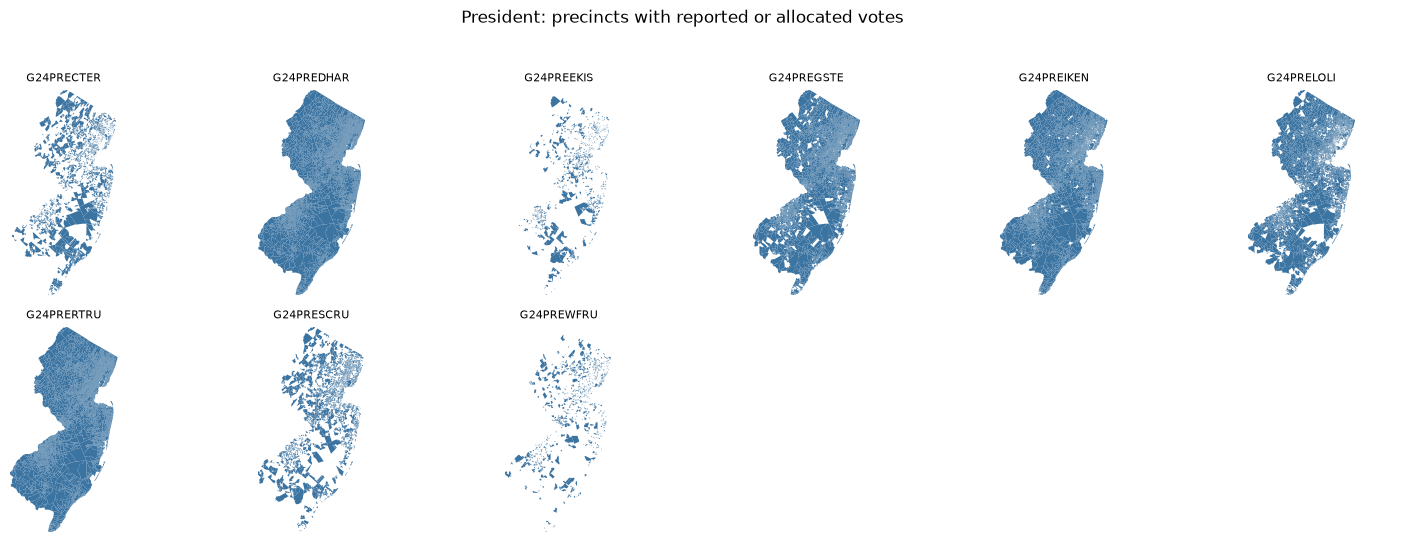

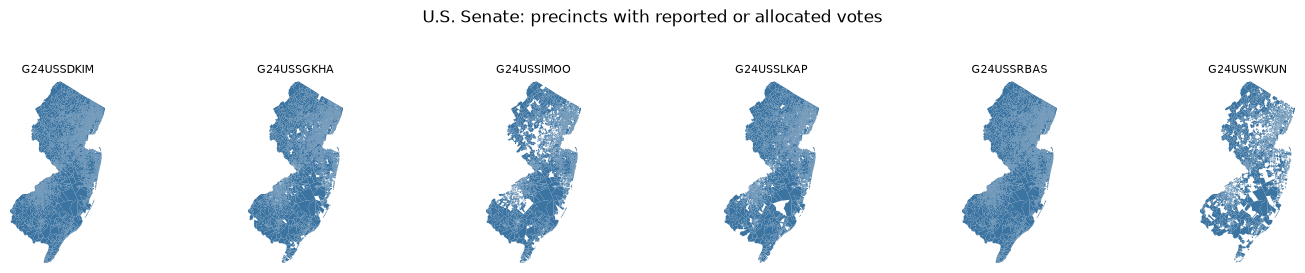

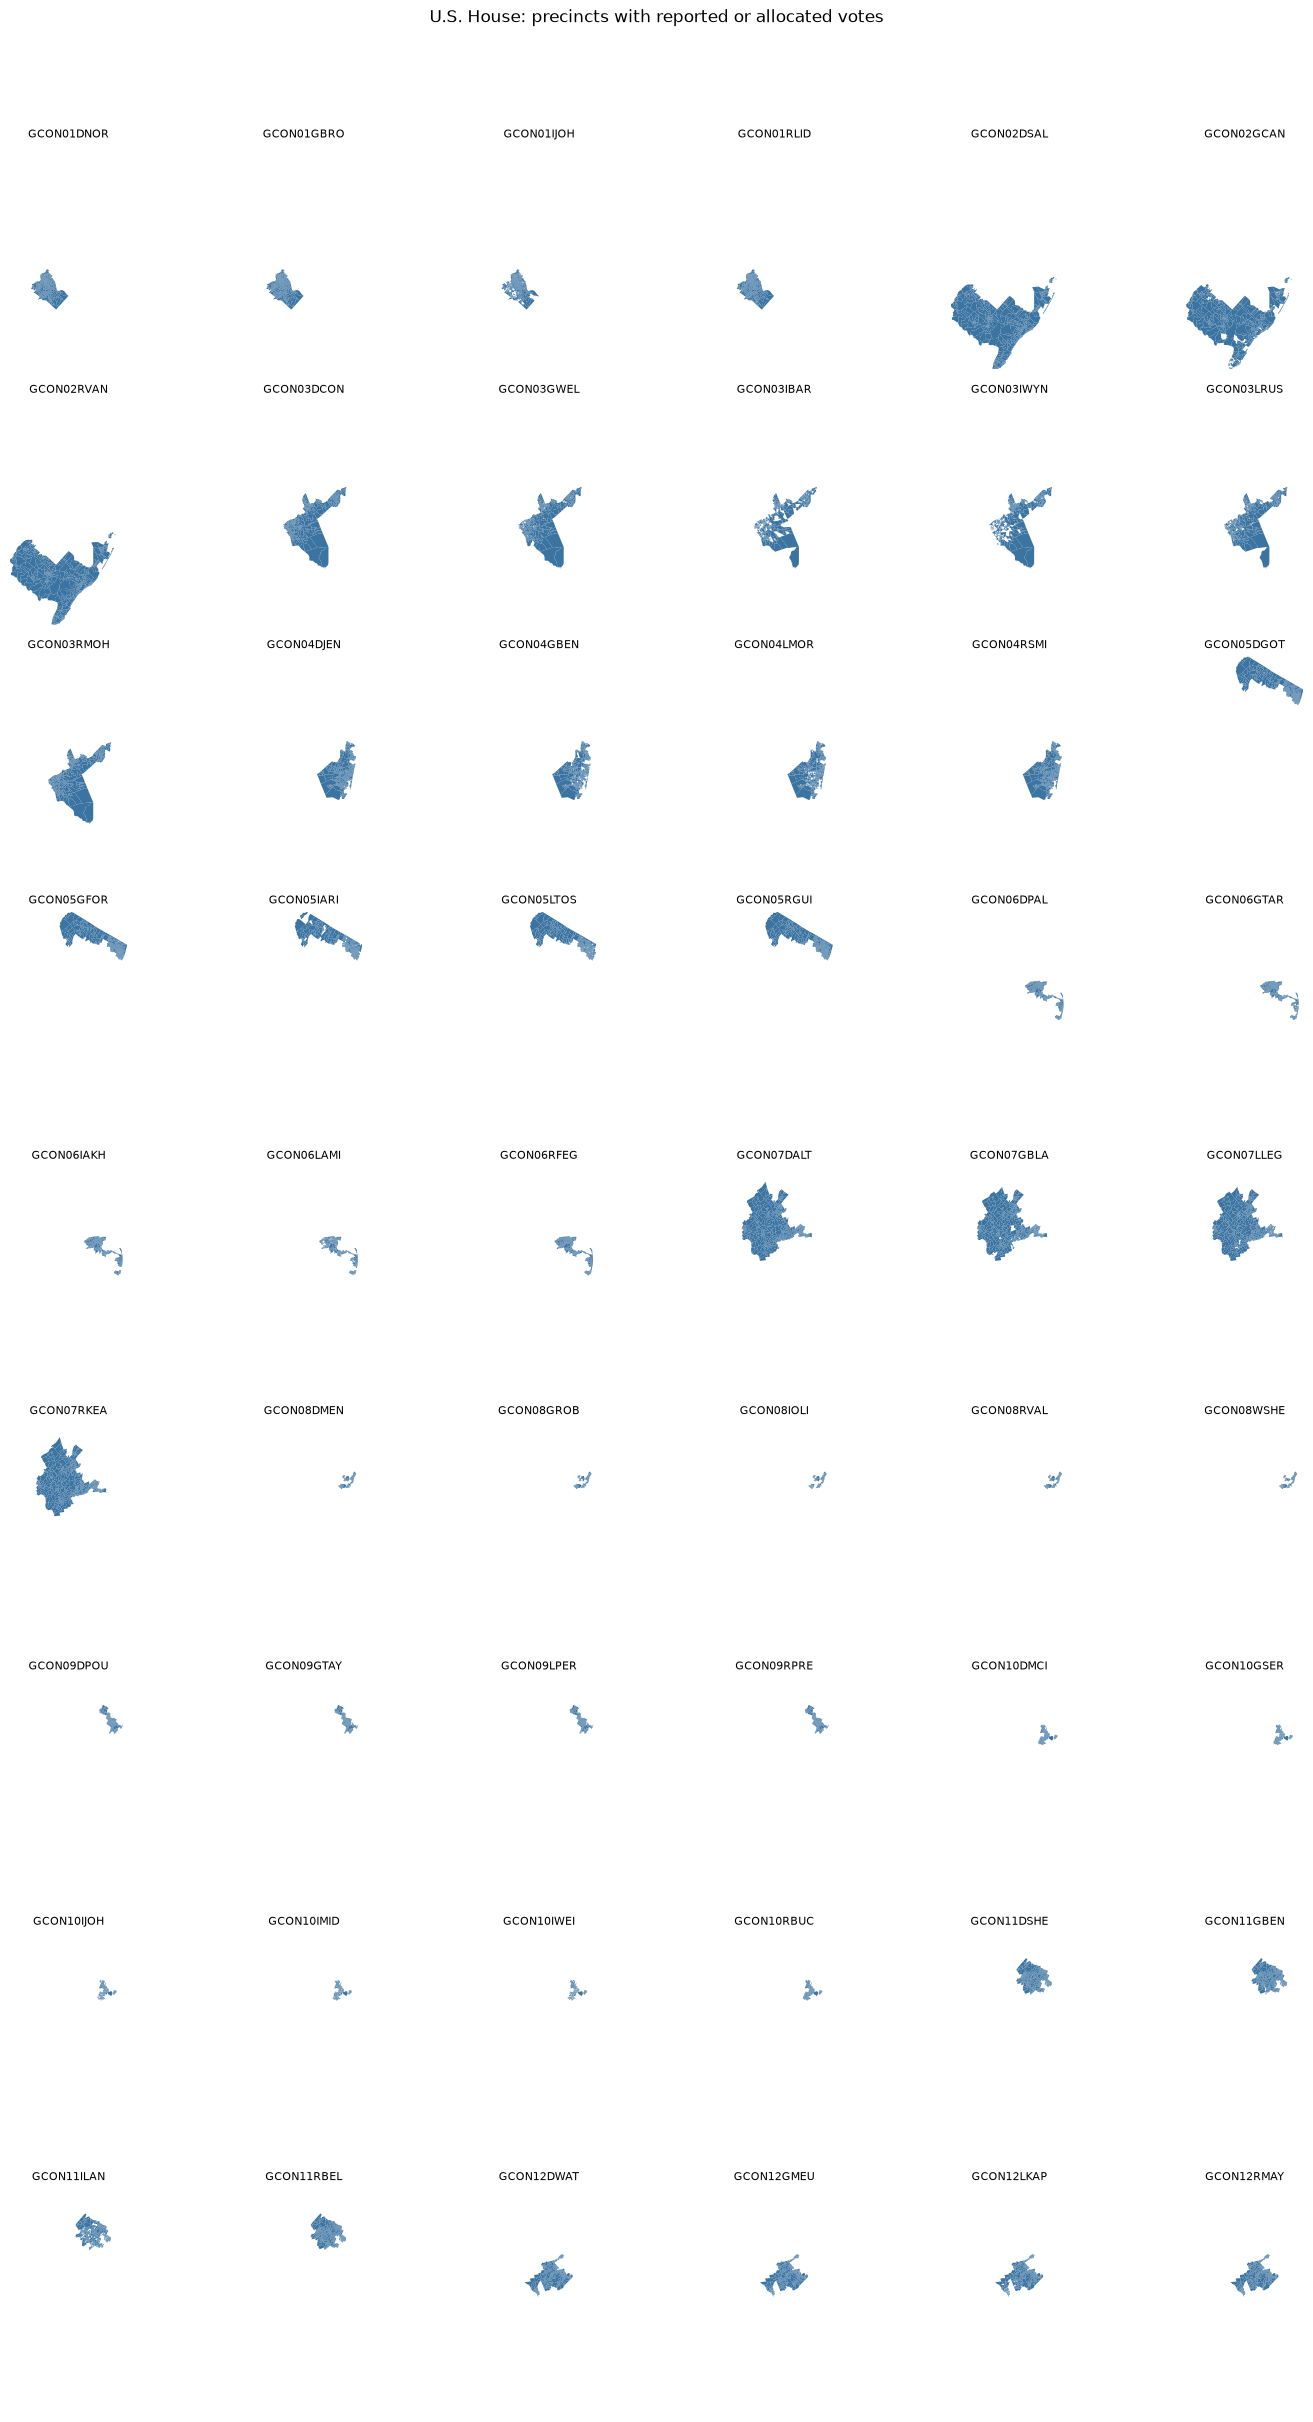

In [18]:
plot_vote_columns(main, VOTE_COLUMNS)